# GPU data collection: CPU vs GPU vectorization vs kernel fusion

A small re-implementation of the two ideas in *Optimizing Data Collection in Deep Reinforcement
Learning* (Gleeson et al., MLBench 2022, arXiv 2207.07736), on the **CartPole** simulator.
The GPU kernels are written by hand in Python with Numba CUDA (`@cuda.jit`); no PyTorch, JAX or XLA.

| Approach | File | What it does |
|---|---|---|
| CPU baseline | `src/cpu_baseline.py` | plain Python, one core, loop over the N games, K steps |
| GPU vectorization | `src/gpu_vectorized.py` | one thread per game, **K kernel launches** (1 step each) |
| GPU kernel fusion | `src/gpu_fused.py` | one thread per game, **1 launch** running K steps in registers |

**N** = number of games simulated in parallel, **K** = steps per data-collection iteration,
so one iteration collects **N x K samples**. We measure samples per second.

**How to use this notebook**
1. Use a machine with an NVIDIA GPU (for example Colab: *Runtime -> Change runtime type -> GPU*).
2. Run the cells from top to bottom. Every code cell has a heading above it that says what it does.
3. The cells that start with `%%writefile` write the project's source files to disk (the code is
   exactly the project's code), so this notebook is self-contained.
4. Results (CSV, plots, animation) are written to the `results/` folder.

**This version includes the live simulation demo** (Steps 12 and 25). The benchmark-only version is `GPU_RL_Benchmark.ipynb`.

## Step 1 - Install the libraries and check the GPU

Installs the three libraries we need (`numpy` for arrays, `numba` for compiling GPU kernels from Python,
`matplotlib` for plots), then asks Numba whether it can see a CUDA GPU.
The output must say `CUDA available: True` and list your GPU. If it says `False`, switch the
runtime to a GPU (Colab) or update the NVIDIA driver, then restart and run this cell again.

In [1]:
!pip install -q numpy numba matplotlib
from numba import cuda
print("CUDA available:", cuda.is_available())
cuda.detect()

CUDA available: True
Found 1 CUDA devices
id 0                Tesla T4                              [SUPPORTED]
                      Compute Capability: 7.5
                           PCI Device ID: 4
                              PCI Bus ID: 0
                                    UUID: GPU-200da293-2c84-85f1-a0d9-cb7d413dd9da
                                Watchdog: Disabled
             FP32/FP64 Performance Ratio: 32
                            FP16 Support: Yes
                            BF16 Support: No
                             FP8 Support: No
Summary:
	1/1 devices are supported


True

## Step 2 - Create the project folders

Makes the folders the later cells write into: `src/` (the programs), `scripts/` (analysis and plots),
`tests/` (correctness checks) and `results/` (all outputs).

In [2]:
!mkdir -p src scripts tests results

## Step 3 - The CartPole simulator (`src/cartpole.py`)

The simulator shared by all three approaches, so they all do exactly the same math.
It contains:
- the **gym CartPole-v1** constants and one physics step (state = 4 floats: cart position, cart velocity,
  pole angle, pole angular velocity), all in `float32` so the GPU does cheap 32-bit math;
- a hash-based **random number generator** that depends only on (seed, game, step, stream), so every
  approach sees the same actions and resets without storing generator state;
- `step_game`: pick an action, apply the physics, and **reset** the game if the cart or pole went out
  of range, so every game does exactly K steps.

`build_sim(jit)` defines these functions once; passing `lambda f: f` keeps them plain Python (CPU) and
passing `cuda.jit(device=True)` compiles the same source for the GPU.
Things the paper does **not** specify (our choices): the equations (gym's), how actions are chosen, and how resets work.

In [ ]:
%%writefile src/cartpole.py

import math
from types import SimpleNamespace

import numpy as np

f32 = np.float32

GRAVITY = f32(9.8)
MASS_CART = f32(1.0)
MASS_POLE = f32(0.1)
TOTAL_MASS = MASS_CART + MASS_POLE
POLE_HALF_LEN = f32(0.5)
POLEMASS_LEN = MASS_POLE * POLE_HALF_LEN
FORCE_MAG = f32(10.0)
TAU = f32(0.02)
X_LIMIT = f32(2.4)
THETA_LIMIT = f32(0.20943951)
FOUR_THIRDS = f32(4.0) / f32(3.0)

ONE_OVER_2_24 = f32(1.0 / 16777216.0)
HALF = f32(0.5)
TENTH = f32(0.1)
FIVE_HUNDREDTH = f32(0.05)

INIT_STEP = 0xFFFFFFFF


def build_sim(jit):
    """Build the simulator functions using jit."""

    @jit
    def hash32(x):
        x ^= x >> 16
        x = (x * 0x7FEB352D) & 0xFFFFFFFF
        x ^= x >> 15
        x = (x * 0x846CA68B) & 0xFFFFFFFF
        x ^= x >> 16
        return x

    @jit
    def rand01(seed, game, t, stream):
        h = hash32(hash32(hash32(seed) ^ t) ^ (game * 8 + stream))
        return f32(h >> 8) * ONE_OVER_2_24

    @jit
    def initial_state(seed, game, t):
        x = rand01(seed, game, t, 0) * TENTH - FIVE_HUNDREDTH
        v = rand01(seed, game, t, 1) * TENTH - FIVE_HUNDREDTH
        th = rand01(seed, game, t, 2) * TENTH - FIVE_HUNDREDTH
        w = rand01(seed, game, t, 3) * TENTH - FIVE_HUNDREDTH
        return x, v, th, w

    @jit
    def choose_action(seed, game, t):
        if rand01(seed, game, t, 4) < HALF:
            return 1
        return 0

    @jit
    def physics(x, v, th, w, action):
        if action == 1:
            force = FORCE_MAG
        else:
            force = -FORCE_MAG

        c = f32(math.cos(th))
        s = f32(math.sin(th))

        temp = (force + POLEMASS_LEN * w * w * s) / TOTAL_MASS
        th_acc = (GRAVITY * s - c * temp) / (
            POLE_HALF_LEN
            * (FOUR_THIRDS - MASS_POLE * c * c / TOTAL_MASS)
        )
        x_acc = temp - POLEMASS_LEN * th_acc * c / TOTAL_MASS

        x = x + TAU * v
        v = v + TAU * x_acc
        th = th + TAU * w
        w = w + TAU * th_acc

        return x, v, th, w

    @jit
    def step_game(x, v, th, w, game, t, seed):
        x, v, th, w = physics(
            x, v, th, w, choose_action(seed, game, t)
        )

        if abs(x) > X_LIMIT or abs(th) > THETA_LIMIT:
            x, v, th, w = initial_state(seed, game, t)
            return x, v, th, w, 1

        return x, v, th, w, 0

    return SimpleNamespace(
        step_game=step_game,
        initial_state=initial_state,
        choose_action=choose_action,
    )

Writing src/cartpole.py


## Step 4 - Shared helpers (`src/common.py`)

Small helpers used by all three programs: command-line arguments (`N K`, `--sweep`, `--reps`, ...),
the sweep settings (N = 2^0..2^20 in steps of x4, K in {1, 10, 100, 1000}), the CPU limits (the CPU runs only up to 262,144 games, and large CPU runs are timed once),
the median-time and result-hash functions, and the one-line CSV output format
`approach,N,K,reps,median_ms,samples_per_sec,state_hash`. It also holds `print_report`, which prints a readable
INPUT / OUTPUT report of one run when a program is started with `--report` (see the "Try each approach once" step). No GPU code here.

In [ ]:
%%writefile src/common.py

import argparse
import hashlib
import statistics
import sys

import numpy as np


SWEEP_NS = [2 ** e for e in range(0, 21, 2)]
SWEEP_KS = [1, 10, 100, 1000]
CPU_MAX_N = 262_144
CPU_FULL_REPS_MAX_SAMPLES = 2_000_000

CSV_HEADER = "approach,N,K,reps,median_ms,samples_per_sec,state_hash"


def parse_args(default_reps):
    p = argparse.ArgumentParser(
        description="usage: program N K   or   program --sweep"
    )
    p.add_argument(
        "N", type=int, nargs="?", default=1024,
        help="number of parallel games"
    )
    p.add_argument(
        "K", type=int, nargs="?", default=100,
        help="steps per iteration"
    )
    p.add_argument(
        "--sweep", action="store_true",
        help="run the whole N x K sweep"
    )
    p.add_argument(
        "--reps", type=int, default=default_reps,
        help="timed repetitions (median)"
    )
    p.add_argument("--seed", type=int, default=42)
    p.add_argument(
        "--save",
        help="write final states (float32 N x 4) to this file"
    )
    p.add_argument(
        "--traj",
        help="(CPU only) write a few trajectories for the animation"
    )
    p.add_argument(
        "--report", action="store_true",
        help="print a readable input/output report"
    )
    return p.parse_args()


def median_ms(times_s):
    return statistics.median(times_s) * 1000.0


def state_hash(states):
    """Return a hash of the final states."""
    return hashlib.sha1(
        np.ascontiguousarray(states).tobytes()
    ).hexdigest()[:16]


def print_result(approach, N, K, reps, ms, final_states, save=None):
    """Print the results as a CSV line."""
    samples_per_sec = N * K / (ms / 1000.0)

    print(
        f"{approach},{N},{K},{reps},{ms:.5f},"
        f"{samples_per_sec:.6e},{state_hash(final_states)}",
        flush=True
    )

    if save:
        np.ascontiguousarray(
            final_states, dtype=np.float32
        ).tofile(save)


def gpu_name():
    from numba import cuda

    try:
        name = cuda.get_current_device().name
    except Exception:
        return "unknown GPU"

    return name.decode() if isinstance(name, bytes) else str(name)


def _rows(states):
    return "\n".join(
        f"      game {i}: [x, v, theta, omega] = "
        f"[{', '.join(f'{float(v): .5f}' for v in row)}]"
        for i, row in enumerate(states)
    )


def print_report(
    approach, N, K, reps, seed, times, init_rows, final_states,
    launches, copy_back_s=0.0, launch_config=None, device=None
):
    """Print a summary of the run to stderr, keeping stdout clean."""
    ms = [t * 1000.0 for t in times]
    med = statistics.median(ms)

    where = (
        f"{device}, {launch_config[0]} blocks x "
        f"{launch_config[1]} threads"
        if device else "CPU, 1 core"
    )

    lines = [
        f"==================== RUN REPORT: {approach} ====================",
        "INPUT",
        f"  games simulated (N)        : {N:,}",
        f"  steps per iteration (K)    : {K:,}",
        f"  seed / repetitions         : {seed} / {reps}",
        "  simulator                  : CartPole (gym v1 equations, float32)",
        "  restart rule               : a game restarts if |x| > 2.4 or |theta| > 12 degrees",
        "  actions                    : push left/right, chosen by a hash of (game, step)",
        f"  runs on                    : {where}",
        "  initial states (first games):",
        _rows(init_rows),
        "OUTPUT",
        "  final states (first games) :",
        _rows(final_states[:len(init_rows)]),
        f"  iterations (steps K)       : {K:,}",
        f"  samples collected (N x K)  : {N * K:,}",
        f"  kernel launches            : {launches:,}",
        f"  execution time (median)    : {med:.3f} ms   (min {min(ms):.3f}, max {max(ms):.3f} over {reps} runs)",
        f"  copy final states to CPU   : {copy_back_s * 1000.0:.3f} ms   (once, at the end)",
        f"  TOTAL time                 : {med + copy_back_s * 1000.0:.3f} ms",
        f"  throughput                 : {N * K / (med / 1000.0):.3e} samples/s",
        f"  final-state hash           : {state_hash(final_states)}",
    ]

    print("\n".join(lines), file=sys.stderr)

Writing src/common.py


## Step 5 - Approach 0: CPU baseline (`src/cpu_baseline.py`)

The status-quo baseline: plain Python on one CPU core. For every step it loops over all N games and
advances each one by one tick (K steps x N games, one game after another).
It also counts how many episodes ended (a sanity check: random-action CartPole lasts about 22 steps)
and can record a few game trajectories (`--traj`) for the animation.

In [ ]:
%%writefile src/cpu_baseline.py

import sys
import time

import numpy as np

from cartpole import build_sim, INIT_STEP
from common import (
    parse_args,
    median_ms,
    print_result,
    print_report,
    SWEEP_NS,
    SWEEP_KS,
    CPU_MAX_N,
    CPU_FULL_REPS_MAX_SAMPLES,
)

sim = build_sim(lambda f: f)
step_game = sim.step_game


def initial_states(N, seed):
    """Generate the initial states for all games."""
    s = np.empty((N, 4), dtype=np.float32)

    for i in range(N):
        s[i] = sim.initial_state(seed, i, INIT_STEP)

    return s


def collect(states, N, K, seed):
    """Run K steps for N games and count the completed episodes."""
    episodes = 0

    for t in range(K):
        for i in range(N):
            x, v, th, w, done = step_game(
                states[i, 0],
                states[i, 1],
                states[i, 2],
                states[i, 3],
                i,
                t,
                seed,
            )

            states[i, 0] = x
            states[i, 1] = v
            states[i, 2] = th
            states[i, 3] = w

            episodes += done

    return episodes


def run(N, K, reps, seed, save=None, report=False):
    init = initial_states(N, seed)
    times = []

    for _ in range(reps):
        states = init.copy()
        t0 = time.perf_counter()
        episodes = collect(states, N, K, seed)
        times.append(time.perf_counter() - t0)

    print_result("cpu", N, K, reps, median_ms(times), states, save)

    if episodes:
        print(
            f"sanity: {episodes} episodes ended, mean length {N * K / episodes:.1f} steps",
            file=sys.stderr,
        )

    if report:
        print_report(
            "cpu", N, K, reps, seed, times, init[:3], states, launches=0
        )


def write_trajectories(path, seed):
    """Save a few game trajectories for the animation."""
    with open(path, "w") as f:
        f.write("game,t,x,v,theta,omega,action\n")

        for g in range(4):
            x, v, th, w = sim.initial_state(seed, g, INIT_STEP)

            for t in range(300):
                f.write(
                    f"{g},{t},{x:.7f},{v:.7f},{th:.7f},{w:.7f},"
                    f"{sim.choose_action(seed, g, t)}\n"
                )

                x, v, th, w, _ = step_game(x, v, th, w, g, t, seed)


if __name__ == "__main__":
    a = parse_args(default_reps=3)

    if a.sweep:
        for K in SWEEP_KS:
            for N in SWEEP_NS:
                if N <= CPU_MAX_N:
                    reps = (
                        a.reps
                        if N * K <= CPU_FULL_REPS_MAX_SAMPLES
                        else 1
                    )
                    run(N, K, reps, a.seed)
    else:
        run(a.N, a.K, a.reps, a.seed, a.save, a.report)

    if a.traj:
        write_trajectories(a.traj, a.seed)

Writing src/cpu_baseline.py


## Step 6 - Approach 1: GPU vectorization (`src/gpu_vectorized.py`)

All N games run in parallel, one GPU thread per game, **but every step is its own kernel launch**.
So K steps mean K launches, and each launch reads the states from slow global memory and writes them back.
Contains: `init_kernel` (writes the initial states), `step_kernel` (one step for every game), and `run`,
which times K back-to-back launches with a GPU synchronize before stopping the clock.

In [ ]:
%%writefile src/gpu_vectorized.py

import sys
import time

import numpy as np
from numba import cuda

from cartpole import build_sim, INIT_STEP
from common import (parse_args, median_ms, print_result, print_report, gpu_name,
                    SWEEP_NS, SWEEP_KS)

sim = build_sim(cuda.jit(device=True))
step_game = sim.step_game
initial_state = sim.initial_state

THREADS = 256


@cuda.jit
def init_kernel(states, seed):
    """Initialize the states for all games."""
    i = cuda.grid(1)
    if i < states.shape[0]:
        x, v, th, w = initial_state(seed, i, INIT_STEP)
        states[i, 0] = x
        states[i, 1] = v
        states[i, 2] = th
        states[i, 3] = w


@cuda.jit
def step_kernel(states, t, seed):
    """Run one step for each game."""
    i = cuda.grid(1)
    if i < states.shape[0]:
        x = states[i, 0]
        v = states[i, 1]
        th = states[i, 2]
        w = states[i, 3]

        x, v, th, w, done = step_game(x, v, th, w, i, t, seed)

        states[i, 0] = x
        states[i, 1] = v
        states[i, 2] = th
        states[i, 3] = w


def run(N, K, reps, seed, save=None, report=False):
    d_states = cuda.device_array((N, 4), dtype=np.float32)
    blocks = (N + THREADS - 1) // THREADS

    init = init_kernel[blocks, THREADS]
    step = step_kernel[blocks, THREADS]

    def collect():
        for t in range(K):
            step(d_states, t, seed)

    init(d_states, seed)
    init_rows = d_states[:3].copy_to_host()
    collect()
    cuda.synchronize()

    times = []
    for _ in range(reps):
        init(d_states, seed)
        cuda.synchronize()

        t0 = time.perf_counter()
        collect()
        cuda.synchronize()
        times.append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    final = d_states.copy_to_host()
    copy_s = time.perf_counter() - t0

    print_result("gpu_vectorized", N, K, reps, median_ms(times), final, save)

    if report:
        print_report("gpu_vectorized", N, K, reps, seed, times, init_rows, final,
                     launches=K, copy_back_s=copy_s,
                     launch_config=(blocks, THREADS), device=gpu_name())


if __name__ == "__main__":
    if not cuda.is_available():
        sys.exit("No CUDA GPU found by Numba. See README (Setup).")

    a = parse_args(default_reps=10)

    if a.sweep:
        for K in SWEEP_KS:
            for N in SWEEP_NS:
                run(N, K, a.reps, a.seed)
    else:
        run(a.N, a.K, a.reps, a.seed, a.save, a.report)

Writing src/gpu_vectorized.py


## Step 7 - Approach 2: GPU kernel fusion (`src/gpu_fused.py`)

The same simulator and the same one-thread-per-game layout, with one change: the loop over the K steps moves
**inside** the kernel. Each thread reads its state once into registers (tiny and very fast), runs all K steps there,
and writes the result once. That is one launch instead of K, and global memory is touched twice instead of 2K times.

In [ ]:
%%writefile src/gpu_fused.py

import sys
import time

import numpy as np
from numba import cuda

from cartpole import build_sim, INIT_STEP
from common import (parse_args, median_ms, print_result, print_report, gpu_name,
                    SWEEP_NS, SWEEP_KS)

sim = build_sim(cuda.jit(device=True))
step_game = sim.step_game
initial_state = sim.initial_state

THREADS = 256


@cuda.jit
def init_kernel(states, seed):
    """Initialize the states for all games."""
    i = cuda.grid(1)
    if i < states.shape[0]:
        x, v, th, w = initial_state(seed, i, INIT_STEP)
        states[i, 0] = x
        states[i, 1] = v
        states[i, 2] = th
        states[i, 3] = w


@cuda.jit
def fused_kernel(states, K, seed):
    """Run K steps for each game in a single kernel launch."""
    i = cuda.grid(1)
    if i < states.shape[0]:
        x = states[i, 0]
        v = states[i, 1]
        th = states[i, 2]
        w = states[i, 3]

        for t in range(K):
            x, v, th, w, done = step_game(x, v, th, w, i, t, seed)

        states[i, 0] = x
        states[i, 1] = v
        states[i, 2] = th
        states[i, 3] = w


def run(N, K, reps, seed, save=None, report=False):
    d_states = cuda.device_array((N, 4), dtype=np.float32)
    blocks = (N + THREADS - 1) // THREADS

    init = init_kernel[blocks, THREADS]
    fused = fused_kernel[blocks, THREADS]

    init(d_states, seed)
    init_rows = d_states[:3].copy_to_host()
    fused(d_states, K, seed)
    cuda.synchronize()

    times = []
    for _ in range(reps):
        init(d_states, seed)
        cuda.synchronize()

        t0 = time.perf_counter()
        fused(d_states, K, seed)
        cuda.synchronize()
        times.append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    final = d_states.copy_to_host()
    copy_s = time.perf_counter() - t0

    print_result("gpu_fused", N, K, reps, median_ms(times), final, save)

    if report:
        print_report("gpu_fused", N, K, reps, seed, times, init_rows, final,
                     launches=1, copy_back_s=copy_s,
                     launch_config=(blocks, THREADS), device=gpu_name())


if __name__ == "__main__":
    if not cuda.is_available():
        sys.exit("No CUDA GPU found by Numba. See README (Setup).")

    a = parse_args(default_reps=10)

    if a.sweep:
        for K in SWEEP_KS:
            for N in SWEEP_NS:
                run(N, K, a.reps, a.seed)
    else:
        run(a.N, a.K, a.reps, a.seed, a.save, a.report)

Writing src/gpu_fused.py


## Step 8 - Experiment runner (`src/run_sweeps.py`)

Runs the three programs over the whole sweep and collects their output lines into `results/timing.csv`,
printing progress as it goes. It then makes a few extra files: the final states of each approach
(for the correctness comparison) and the recorded trajectories (for the animation). Finally it writes the **sweep report**
(`results/report_all.md` and `results/summary_all.csv`: one table per K plus key findings) by calling `scripts/report.py --all`.

In [ ]:
%%writefile src/run_sweeps.py

import os
import subprocess
import sys

from common import CSV_HEADER

HERE = os.path.dirname(os.path.abspath(__file__))
RESULTS = os.path.join(os.path.dirname(HERE), "results")
os.makedirs(RESULTS, exist_ok=True)
OUT = os.path.join(RESULTS, "timing.csv")


def script(name):
    return [sys.executable, os.path.join(HERE, name)]


with open(OUT, "w") as out:
    out.write(CSV_HEADER + "\n")

    for name in ("gpu_vectorized.py", "gpu_fused.py", "cpu_baseline.py"):
        print(f"--- {name} --sweep", flush=True)

        proc = subprocess.Popen(
            script(name) + ["--sweep"],
            stdout=subprocess.PIPE,
            text=True,
        )

        for line in proc.stdout:
            print(line, end="", flush=True)
            out.write(line)
            out.flush()

        if proc.wait() != 0:
            sys.exit(f"{name} failed")


print("--- extra files", flush=True)

extras = [
    ("cpu_baseline.py", [
        "--save", os.path.join(RESULTS, "final_cpu.bin"),
        "--traj", os.path.join(RESULTS, "trajectory.csv"),
    ]),
    ("gpu_vectorized.py", [
        "--save", os.path.join(RESULTS, "final_vectorized.bin"),
    ]),
    ("gpu_fused.py", [
        "--save", os.path.join(RESULTS, "final_fused.bin"),
    ]),
]

for name, extra in extras:
    subprocess.run(
        script(name) + ["1024", "10", "--reps", "1"] + extra,
        stdout=subprocess.DEVNULL,
        check=True,
    )


print("--- sweep report (results/report_all.md)", flush=True)

subprocess.run(
    [
        sys.executable,
        os.path.join(os.path.dirname(HERE), "scripts", "report.py"),
        "--all",
    ],
    cwd=os.path.dirname(HERE),
    check=True,
)

print("Done. Now run:  python scripts/compare.py  and  python scripts/plot.py")

Writing src/run_sweeps.py


## Step 9 - Correctness comparison (`scripts/compare.py`)

Compares the final game states written by two programs. Vectorized and fused must be **bit-identical**.
CPU versus GPU may differ in the last bits, because the CPU and GPU math libraries compute `sin`/`cos` slightly
differently, so that pair only has to be very close.

In [ ]:
%%writefile scripts/compare.py

import sys
from array import array


def load(path):
    a = array("f")
    with open(path, "rb") as f:
        a.frombytes(f.read())
    return a


def compare(name_a, name_b):
    a, b = load(name_a), load(name_b)
    assert len(a) == len(b), "different sizes"

    diffs = [abs(x - y) for x, y in zip(a, b)]
    worst = max(diffs)
    games = len(a) // 4
    bad = len({i // 4 for i, d in enumerate(diffs) if d > 1e-3})

    print(f"{name_a}  vs  {name_b}")
    print(f"  identical bits: {a == b} | max abs difference: {worst:.2e} | "
          f"games differing by > 1e-3: {bad} of {games}")

    return a == b, worst


if len(sys.argv) == 3:
    compare(sys.argv[1], sys.argv[2])
else:
    same, _ = compare("results/final_vectorized.bin", "results/final_fused.bin")
    print("  PASS" if same else "  FAIL: vectorized and fused must be bit-identical")

    _, worst = compare("results/final_cpu.bin", "results/final_fused.bin")
    print("  PASS" if worst < 1e-3 else "  FAIL: CPU and GPU differ too much")

Writing scripts/compare.py


## Step 10 - Plots and report numbers (`scripts/plot.py`)

Reads `results/timing.csv`, checks that vectorized and fused hashes match in every configuration, and draws four plots:
1. throughput vs N (one panel per K), 2. time per approach for one configuration (bar chart),
3. fusion speedup at equal K (vectorized time / fused time), 4. throughput vs K.
It also prints the numbers for the report (times and speedups). By default the bar chart and the printed numbers use the **largest
configuration measured** (N = 1,048,576 games, K = 1,000 steps, about 1 billion samples; the CPU is not run there, so it shows GPU vectorized
vs GPU fused only) and a second bar chart for the **largest configuration that includes the CPU**. Add `N K` after the script name to choose another.

In [ ]:
%%writefile scripts/plot.py

import csv
import sys

import matplotlib.pyplot as plt

APPROACHES = ["cpu", "gpu_vectorized", "gpu_fused"]
LABELS = {"cpu": "CPU (1 core)", "gpu_vectorized": "GPU vectorized (K launches)",
          "gpu_fused": "GPU fused (1 launch)"}
COLORS = {"cpu": "tab:gray", "gpu_vectorized": "tab:blue", "gpu_fused": "tab:red"}

rows = {}
for r in csv.DictReader(open("results/timing.csv")):
    rows[(r["approach"], int(r["N"]), int(r["K"]))] = r

Ns = sorted({k[1] for k in rows})
Ks = sorted({k[2] for k in rows})


def ms(a, N, K):
    r = rows.get((a, N, K))
    return float(r["median_ms"]) if r else None


def tput(a, N, K):
    r = rows.get((a, N, K))
    return float(r["samples_per_sec"]) if r else None


bad = [(N, K) for a, N, K in rows
       if a == "gpu_fused" and ("gpu_vectorized", N, K) in rows
       and rows[("gpu_fused", N, K)]["state_hash"] != rows[("gpu_vectorized", N, K)]["state_hash"]]

total = sum(1 for a, N, K in rows
            if a == "gpu_fused" and ("gpu_vectorized", N, K) in rows)

print(f"Correctness: vectorized == fused (bit for bit) in {total - len(bad)} of {total} configs")
if bad:
    print("  MISMATCH at (N, K):", bad)


fig, axes = plt.subplots(1, len(Ks), figsize=(4 * len(Ks), 3.8), sharey=True)

for ax, K in zip(axes, Ks):
    for a in APPROACHES:
        pts = [(N, tput(a, N, K)) for N in Ns if tput(a, N, K)]
        if pts:
            ax.plot(*zip(*pts), marker="o", color=COLORS[a], label=LABELS[a])

    ax.set(xscale="log", yscale="log", title=f"K = {K}", xlabel="Parallel games (N)")
    ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel("Throughput (samples / second)")
axes[0].legend(fontsize=7)
fig.suptitle("Data-collection throughput vs number of games")
fig.tight_layout()
fig.savefig("results/plot1_throughput_vs_N.png", dpi=130)


def pick_configs():
    gpu = [(k[1], k[2]) for k in rows if k[0] == "gpu_fused"]
    cpu = [(k[1], k[2]) for k in rows if k[0] == "cpu"]
    size = lambda c: (c[0] * c[1], c[0])
    return max(gpu, key=size) if gpu else None, max(cpu, key=size) if cpu else None


if len(sys.argv) > 2:
    big, with_cpu = (int(sys.argv[1]), int(sys.argv[2])), None
else:
    big, with_cpu = pick_configs()

N0, K0 = big


def bars(N, K, filename):
    have = [(a, ms(a, N, K)) for a in APPROACHES if ms(a, N, K)]
    missing = [a for a in APPROACHES if not ms(a, N, K)]

    if missing:
        print(f"NOTE: N={N:,}, K={K:,}: no timing for {missing} "
              "(the CPU is only run up to 262,144 games, pure Python is too slow beyond that).")
    if not have:
        return

    fig, ax = plt.subplots(figsize=(6, 3.8))
    bars_ = ax.bar([LABELS[a] for a, _ in have], [t for _, t in have],
                   color=[COLORS[a] for a, _ in have])

    if "cpu" in missing:
        ax.set_ylabel("Time (ms)")
        ax.set_ylim(0, max(t for _, t in have) * 1.15)
        ax.text(0.98, 0.95, "CPU not run at this size", transform=ax.transAxes,
                ha="right", va="top", fontsize=8)
    else:
        ax.set_yscale("log")
        ax.set_ylabel("Time (ms, log scale)")

    ax.set_title(f"Time to collect {N * K:,} samples (N={N:,}, K={K:,})", fontsize=10)

    for b, (_, t) in zip(bars_, have):
        ax.text(b.get_x() + b.get_width() / 2, t, f"{t:.3g} ms",
                ha="center", va="bottom")

    plt.setp(ax.get_xticklabels(), fontsize=7)
    fig.tight_layout()
    fig.savefig(filename, dpi=130)


bars(N0, K0, "results/plot2_time_bars.png")
if with_cpu and with_cpu != big:
    bars(*with_cpu, "results/plot2b_time_bars_with_cpu.png")


fig, ax = plt.subplots(figsize=(6, 4))

for K in Ks:
    pts = [(N, ms("gpu_vectorized", N, K) / ms("gpu_fused", N, K))
           for N in Ns if ms("gpu_vectorized", N, K) and ms("gpu_fused", N, K)]
    if pts:
        ax.plot(*zip(*pts), marker="o", label=f"K = {K}")

ax.set(xscale="log", yscale="log", xlabel="Parallel games (N)",
       ylabel="Fusion speedup (x)",
       title="Fusion speedup at equal K (K launches vs 1 launch)")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("results/plot3_fusion_speedup.png", dpi=130)


fig, ax = plt.subplots(figsize=(6, 4))

for a in ["gpu_vectorized", "gpu_fused"]:
    pts = [(K, tput(a, N0, K)) for K in Ks if tput(a, N0, K)]
    if pts:
        ax.plot(*zip(*pts), marker="o", color=COLORS[a], label=LABELS[a])

ax.set(xscale="log", yscale="log", xlabel="Steps per iteration (K)",
       ylabel="Throughput (samples / second)", title=f"Effect of K (N = {N0})")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("results/plot4_throughput_vs_K.png", dpi=130)


def numbers(N, K):
    print(f"\nConfiguration N={N:,}, K={K:,}:")
    t = {a: ms(a, N, K) for a in APPROACHES}

    for a in APPROACHES:
        print(f"  {LABELS[a]:30s} {t[a]:12.4f} ms" if t[a]
              else f"  {LABELS[a]:30s}      (not run)")

    if t["cpu"] and t["gpu_vectorized"]:
        print(f"  GPU vectorized vs CPU : {t['cpu'] / t['gpu_vectorized']:8.1f}x")
    if t["cpu"] and t["gpu_fused"]:
        print(f"  GPU fused vs CPU      : {t['cpu'] / t['gpu_fused']:8.1f}x")
    if t["gpu_vectorized"] and t["gpu_fused"]:
        print(f"  Fusion speedup (same K): {t['gpu_vectorized'] / t['gpu_fused']:7.1f}x")

    f1, fK = tput("gpu_fused", N, min(Ks)), tput("gpu_fused", N, max(Ks))
    if f1 and fK:
        print(f"  Paper-style fusion speedup, fused K={max(Ks)} vs K={min(Ks)}: {fK / f1:.1f}x "
              f"(paper: 11.3x on CartPole)")


numbers(N0, K0)
if with_cpu and with_cpu != big:
    numbers(*with_cpu)

print("\nSaved plots to results/plot*.png")

Writing scripts/plot.py


## Step 11 - Animated "race" (`scripts/visualize.py`)

Makes a side-by-side animation of the three approaches collecting data: a cart replaying one recorded game, a
sample counter and a progress bar per approach. The times are the **real measured** times, replayed in slow motion
(the slowest approach takes 8 seconds on screen). It is a replay, not live: a single fused launch cannot be watched while it runs.

In [ ]:
%%writefile scripts/visualize.py

import csv
import math
import sys
import matplotlib

GIF = "--gif" in sys.argv
if GIF:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Rectangle

args = [a for a in sys.argv[1:] if not a.startswith("--")]
DURATION, FPS = 8.0, 25

NAMES = [
    ("cpu", "CPU (1 core)", "tab:gray"),
    ("gpu_vectorized", "GPU vectorized", "tab:blue"),
    ("gpu_fused", "GPU fused", "tab:red"),
]

all_ms = {}
for r in csv.DictReader(open("results/timing.csv")):
    all_ms[(r["approach"], int(r["N"]), int(r["K"]))] = float(r["median_ms"])

by_size = lambda c: (c[0] * c[1], c[0])
WITH_CPU = "--with-cpu" in sys.argv

if len(args) >= 2:
    N, K = int(args[0]), int(args[1])
elif WITH_CPU:
    N, K = max(((k[1], k[2]) for k in all_ms if k[0] == "cpu"), key=by_size)
else:
    N, K = max(((k[1], k[2]) for k in all_ms if k[0] == "gpu_fused"), key=by_size)

time_ms = {a: all_ms[(a, N, K)] for a, _, _ in NAMES if (a, N, K) in all_ms}
shown = [n for n in NAMES if n[0] in time_ms]

if not shown:
    sys.exit(f"No timing for N={N}, K={K} in results/timing.csv")

if len(shown) < 3:
    print("NOTE: missing approaches for this configuration:",
          [n[0] for n in NAMES if n[0] not in time_ms],
          "(use --with-cpu for a configuration with the CPU)")

slowest = max(time_ms[n[0]] for n in shown)

traj = [
    (float(r["x"]), float(r["theta"]))
    for r in csv.DictReader(open("results/trajectory.csv"))
    if r["game"] == "0"
]
STEPS = len(traj)

fig, axes = plt.subplots(1, len(shown), figsize=(4.2 * len(shown), 4.3), squeeze=False)
axes = axes[0]
POLE = 0.7
panels = []

for ax, (key, label, color) in zip(axes, shown):
    ax.set_xlim(-2.8, 2.8)
    ax.set_ylim(-0.7, 1.4)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.plot([-2.4, 2.4], [0, 0], color="black", lw=1)
    ax.plot([-2.4, -2.4], [-0.05, 0.05], color="black")
    ax.plot([2.4, 2.4], [-0.05, 0.05], color="black")

    cart = Rectangle((-0.2, 0), 0.4, 0.25, color=color)
    ax.add_patch(cart)
    pole, = ax.plot([], [], color="saddlebrown", lw=4)

    ax.add_patch(Rectangle((-2.4, -0.55), 4.8, 0.1, fill=False, ec="black"))
    bar = Rectangle((-2.4, -0.55), 0.0, 0.1, color=color)
    ax.add_patch(bar)

    ax.set_title(f"{label}\nreal time: {time_ms[key]:.3g} ms", fontsize=11)
    txt = ax.text(0, 1.2, "", ha="center", fontsize=9)
    panels.append((key, cart, pole, bar, txt))

fig.suptitle(
    f"Collecting N x K = {N * K:,} samples (N = {N:,} games, K = {K} steps)  -  "
    f"slow-motion replay of measured times",
    fontsize=10,
)
fig.tight_layout()


def draw(frame):
    now = frame / FPS

    for key, cart, pole, bar, txt in panels:
        seconds_on_screen = max(DURATION * time_ms[key] / slowest, 1e-9)
        progress = min(1.0, now / seconds_on_screen)
        x, theta = traj[min(STEPS - 1, int(progress * (STEPS - 1)))]

        cart.set_x(x - 0.2)
        pole.set_data(
            [x, x + POLE * math.sin(theta)],
            [0.25, 0.25 + POLE * math.cos(theta)],
        )
        bar.set_width(4.8 * progress)

        done = "  DONE" if progress >= 1.0 else ""
        txt.set_text(f"{progress * N * K:,.0f} samples{done}")

    return []


frames = int((DURATION + 1.5) * FPS)
ani = FuncAnimation(fig, draw, frames=frames, interval=1000 / FPS, blit=False)

if GIF:
    out = "results/race_with_cpu.gif" if WITH_CPU else "results/race.gif"
    ani.save(out, writer=PillowWriter(fps=FPS))
    print(f"Saved {out}  (N={N:,}, K={K:,})")
else:
    plt.show()

Writing scripts/visualize.py


## Step 12 - Live simulation demo (`scripts/live_demo.py`)

A live demo for presentations. The three approaches run **one after the other** (CPU, then GPU vectorized, then GPU fused). Each gets **its own window**
(in a notebook: its own output block, which stays on screen when it finishes; run as a script on a laptop it opens a real separate window per approach).
A robot cart slides left/right while its pole swings, because that approach really computes the simulation: the CPU as a Python loop, vectorized with one kernel launch per step,
fused with one kernel launch per frame. Each approach simulates `--games` games (default 256) and the first game is drawn; a game restarts when its pole leans past 12 degrees.
Drawing and copying the state back are much more expensive than the simulation, so all approaches look equally fast. What differs is the **compute time** counter:
its timer wraps **only the computation** (not the copy-back and not the drawing), so the numbers are not spoiled by the animation.
It is a demo at a small size and is separate from the benchmark; the real benchmark numbers come from the sweep.
The demo uses one extra kernel, a copy of the fused kernel that starts at a given step so the animation can continue across frames.

In [ ]:

%%writefile scripts/live_demo.py

import argparse
import math
import os
import sys
import time

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle
from numba import cuda

sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(__file__)), "..", "src"))
import cpu_baseline
import gpu_vectorized
import gpu_fused

p = argparse.ArgumentParser()
p.add_argument("--games", type=int, default=1000, help="games simulated by each approach")
p.add_argument("--frames", type=int, default=100, help="animation frames per approach")
p.add_argument("--steps-per-frame", type=int, default=4, help="simulation steps between two frames")
p.add_argument("--only", choices=["cpu", "vectorized", "fused"], help="run just one approach")
p.add_argument("--seed", type=int, default=42)
p.add_argument("--save-prefix", help="save the last frame of each approach to <prefix>_<name>.png")
a = p.parse_args()

N, S, SEED = a.games, a.steps_per_frame, a.seed

if not cuda.is_available():
    sys.exit("No CUDA GPU found by Numba (the GPU approaches need one). See README (Setup).")

try:
    from IPython import get_ipython
    from IPython.display import display
    IN_NOTEBOOK = get_ipython() is not None
except ImportError:
    IN_NOTEBOOK = False

WINDOWS = not IN_NOTEBOOK and matplotlib.get_backend().lower() not in (
    "agg", "pdf", "svg", "ps", "cairo", "template"
)

THREADS = gpu_vectorized.THREADS
blocks = (N + THREADS - 1) // THREADS
step_game = gpu_fused.step_game


@cuda.jit
def fused_chunk_kernel(states, t0, steps, seed):
    i = cuda.grid(1)
    if i < states.shape[0]:
        x, v, th, w = states[i, 0], states[i, 1], states[i, 2], states[i, 3]
        for t in range(t0, t0 + steps):
            x, v, th, w, done = step_game(x, v, th, w, i, t, seed)
        states[i, 0], states[i, 1] = x, v
        states[i, 2], states[i, 3] = th, w


cpu_states = cpu_baseline.initial_states(N, SEED)
d_vec = cuda.device_array((N, 4), dtype=np.float32)
d_fus = cuda.device_array((N, 4), dtype=np.float32)

gpu_vectorized.init_kernel[blocks, THREADS](d_vec, SEED)
gpu_fused.init_kernel[blocks, THREADS](d_fus, SEED)

vec_launch = gpu_vectorized.step_kernel[blocks, THREADS]
fused_launch = fused_chunk_kernel[blocks, THREADS]


def advance_cpu(t0):
    for t in range(t0, t0 + S):
        for i in range(N):
            x, v, th, w, _ = cpu_baseline.step_game(
                *cpu_states[i], i, t, SEED
            )
            cpu_states[i] = (x, v, th, w)


def advance_vectorized(t0):
    for t in range(t0, t0 + S):
        vec_launch(d_vec, t, SEED)
    cuda.synchronize()


def advance_fused(t0):
    fused_launch(d_fus, t0, S, SEED)
    cuda.synchronize()


scratch = cuda.device_array((N, 4), dtype=np.float32)
gpu_vectorized.init_kernel[blocks, THREADS](scratch, SEED)
vec_launch(scratch, 0, SEED)
fused_launch(scratch, 0, S, SEED)
cuda.synchronize()

APPROACHES = [
    {"key": "cpu", "name": "CPU (1 core, plain Python)", "color": "#7f7f7f",
     "advance": advance_cpu, "read": lambda: cpu_states[0]},
    {"key": "vectorized", "name": "GPU vectorized (one kernel launch per step)",
     "color": "#1f77b4", "advance": advance_vectorized,
     "read": lambda: d_vec[0:1].copy_to_host()[0]},
    {"key": "fused", "name": "GPU fused (one kernel launch per frame)",
     "color": "#d62728", "advance": advance_fused,
     "read": lambda: d_fus[0:1].copy_to_host()[0]},
]

if a.only:
    APPROACHES = [ap for ap in APPROACHES if ap["key"] == a.only]

POLE_LEN, BODY_Y = 1.15, 0.46


def make_window(ap):
    fig, ax = plt.subplots(figsize=(9, 4.6))
    fig.patch.set_facecolor("#eef4fb")
    ax.set_facecolor("#eef4fb")
    ax.set_xlim(-2.9, 2.9)
    ax.set_ylim(-0.55, 2.05)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.add_patch(Rectangle((-2.9, -0.55), 5.8, 0.5, color="#c9d3dd"))
    ax.add_patch(Rectangle((-2.4, -0.05), 4.8, 0.05, color="#34495e"))

    for end in (-2.4, 2.4):
        ax.add_patch(Rectangle((end - 0.04, -0.05), 0.08, 0.35, color="#c0392b"))

    for sign in (-1, 1):
        lim = 12 * math.pi / 180
        ax.plot(
            [0, sign * POLE_LEN * 1.15 * math.sin(lim)],
            [BODY_Y, BODY_Y + POLE_LEN * 1.15 * math.cos(lim)],
            color="#c0392b", lw=0.8, ls=(0, (4, 4)), alpha=0.35,
        )

    art = {}
    art["pole"], = ax.plot([], [], color="#5d4037", lw=7, solid_capstyle="round", zorder=3)
    art["ball"] = Circle((0, 0), 0.09, color="#e67e22", zorder=4)
    ax.add_patch(art["ball"])

    art["body"] = FancyBboxPatch(
        (-0.3, 0.16), 0.6, 0.32,
        boxstyle="round,pad=0,rounding_size=0.07",
        fc=ap["color"], ec="#222222", lw=1.5, zorder=5,
    )
    ax.add_patch(art["body"])

    art["wheels"] = [
        Circle((0, 0.09), 0.09, fc="#222222", ec="#888888", lw=2, zorder=6)
        for _ in range(2)
    ]
    art["eye"] = Circle((0, 0), 0.075, fc="white", ec="#222222", lw=1, zorder=7)
    art["pupil"] = Circle((0, 0), 0.032, fc="#222222", zorder=8)
    art["hub"] = Circle((0, BODY_Y), 0.045, fc="#bdc3c7", ec="#222222", zorder=9)

    for patch in art["wheels"] + [art["eye"], art["pupil"], art["hub"]]:
        ax.add_patch(patch)

    ax.text(-2.85, 1.98, ap["name"], fontsize=14, fontweight="bold", va="top")
    art["info"] = ax.text(-2.85, 1.72, "", fontsize=11, va="top", family="monospace")
    fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01)
    return fig, art


def draw_frame(art, state, steps_done, compute_s, status):
    x, th = float(state[0]), float(state[2])
    art["body"].set_bounds(x - 0.3, 0.16, 0.6, 0.32)

    for wheel, dx in zip(art["wheels"], (-0.18, 0.18)):
        wheel.center = (x + dx, 0.09)

    art["eye"].center = (x + 0.14, 0.34)
    art["pupil"].center = (x + 0.155, 0.34)
    art["hub"].center = (x, BODY_Y)

    tip = (x + POLE_LEN * math.sin(th), BODY_Y + POLE_LEN * math.cos(th))
    art["pole"].set_data([x, tip[0]], [BODY_Y, tip[1]])
    art["ball"].center = tip

    art["info"].set_text(
        f"steps          {steps_done:>10,}\n"
        f"samples        {steps_done * N:>10,}   ({N:,} games)\n"
        f"compute time   {compute_s * 1000:>10.2f} ms   {status}"
    )


results = []

for ap in APPROACHES:
    fig, art = make_window(ap)
    draw_frame(art, ap["read"](), 0, 0.0, "starting")

    if IN_NOTEBOOK:
        handle = display(fig, display_id=True)
    elif WINDOWS:
        plt.ion()
        plt.show(block=False)

    compute_s = 0.0

    for frame in range(a.frames):
        c0 = time.perf_counter()
        ap["advance"](frame * S)
        compute_s += time.perf_counter() - c0

        state = ap["read"]()
        status = "running" if frame + 1 < a.frames else "DONE"
        draw_frame(art, state, (frame + 1) * S, compute_s, status)

        if IN_NOTEBOOK:
            handle.update(fig)
        elif WINDOWS:
            plt.pause(0.001)

    if a.save_prefix:
        fig.savefig(f"{a.save_prefix}_{ap['key']}.png", dpi=110)

    results.append((ap["name"], compute_s))

    if WINDOWS:
        plt.pause(1.0)
    else:
        plt.close(fig)

if WINDOWS:
    print("Close the windows to finish.")
    plt.ioff()
    plt.show()

total_steps = a.frames * S
print(f"\nDemo compute-only times ({N} games, {total_steps} steps; copy-back and drawing excluded):")

for name, secs in results:
    print(f"  {name:48s} {secs * 1000:10.2f} ms   ({secs / total_steps * 1e6:9.1f} microseconds per step)")

print("These are demo-size numbers. The benchmark numbers come from the sweeps (src/run_sweeps.py).")


Overwriting scripts/live_demo.py


## Step 13 - Final comparison table (`scripts/report.py`)

Reads `results/timing.csv` and builds comparison reports of the three approaches. `python scripts/report.py N K` prints one table for a
chosen configuration; `python scripts/report.py --all` reports the **whole sweep**: one table per K (a row per N, with the times of all
three approaches, the fusion speedup, the speedups versus the CPU, throughput and a vectorized-equals-fused check) and a
**key findings** block computed from the data (peak throughput of each approach, where the GPU first beats the CPU, the range of the
fusion speedup, and the vectorized cost per kernel launch). `--all` saves `results/report_all.md` and `results/summary_all.csv`.
For a single configuration:
iterations (K), samples collected, kernel launches, execution time, throughput, speedup versus the CPU and versus GPU vectorized,
and the final-state hash. Under the table it states whether vectorized and fused gave bit-identical results and which approach was fastest.
The table is also saved as `results/report_N<N>_K<K>.md`. If the CPU was not run for that size, its row says "not run".

In [ ]:

%%writefile scripts/report.py

import csv
import sys

NAMES = {"cpu": "CPU (1 core)", "gpu_vectorized": "GPU vectorized", "gpu_fused": "GPU fused"}

rows = {}
for r in csv.DictReader(open("results/timing.csv")):
    rows[(r["approach"], int(r["N"]), int(r["K"]))] = r

if not rows:
    sys.exit("results/timing.csv is empty")


def ms(a, N, K):
    r = rows.get((a, N, K))
    return float(r["median_ms"]) if r else None


def tput(a, N, K):
    r = rows.get((a, N, K))
    return float(r["samples_per_sec"]) if r else None


def pick_configs():
    gpu = [(k[1], k[2]) for k in rows if k[0] == "gpu_fused"]
    cpu = [(k[1], k[2]) for k in rows if k[0] == "cpu"]
    size = lambda c: (c[0] * c[1], c[0])
    return max(gpu, key=size) if gpu else None, max(cpu, key=size) if cpu else None


def sp(x):
    return f"{x:,.1f}x" if x >= 1 else f"{x:.4f}x"


def md_table(head, body):
    lines = ["| " + " | ".join(head) + " |", "|" + "|".join(["---"] * len(head)) + "|"]
    return lines + ["| " + " | ".join(r) + " |" for r in body]


def one_config(N, K):
    if not any(k[1] == N and k[2] == K for k in rows):
        sys.exit(f"No results for N={N}, K={K} in results/timing.csv")

    launches = {"cpu": 0, "gpu_vectorized": K, "gpu_fused": 1}
    t = {a: ms(a, N, K) for a in NAMES if ms(a, N, K)}

    head = ["Approach", "Iterations (K)", "Samples (N x K)", "Kernel launches",
            "Execution time (ms)", "Throughput (samples/s)", "Speedup vs CPU",
            "Speedup vs GPU vectorized", "Final-state hash"]
    body = []

    for a in NAMES:
        if a not in t:
            body.append([NAMES[a], f"{K:,}", f"{N * K:,}", f"{launches[a]:,}",
                         "not run", "-", "-", "-", "-"])
            continue

        vs_cpu = sp(t["cpu"] / t[a]) if "cpu" in t else "-"
        vs_vec = sp(t["gpu_vectorized"] / t[a]) if "gpu_vectorized" in t else "-"
        body.append([NAMES[a], f"{K:,}", f"{N * K:,}", f"{launches[a]:,}",
                     f"{t[a]:,.3f}", f"{tput(a, N, K):.3e}", vs_cpu, vs_vec,
                     rows[(a, N, K)]["state_hash"]])

    lines = [f"## Comparison of the approaches (N = {N:,} games, K = {K:,} steps)", ""]
    lines += md_table(head, body)
    lines.append("")
    lines.append("Execution time = time to collect all N x K samples (median over the repetitions, "
                 "state copy-back to the CPU not included).")
    lines.append("Repetitions timed: " + ", ".join(
        f"{NAMES[a]} {rows[(a, N, K)]['reps']}" for a in NAMES if (a, N, K) in rows) +
        " (a single repetition is the one measured time, not a median).")

    if "gpu_vectorized" in t and "gpu_fused" in t:
        same = rows[("gpu_vectorized", N, K)]["state_hash"] == rows[("gpu_fused", N, K)]["state_hash"]
        lines.append(f"Correctness: GPU vectorized and GPU fused final states bit-identical: "
                     f"{'YES' if same else 'NO (!)'}.")
        lines.append(f"Fusion speedup at the same K (vectorized time / fused time): "
                     f"{t['gpu_vectorized'] / t['gpu_fused']:.1f}x.")

    if "cpu" in t:
        lines.append("The CPU hash can differ from the GPU hash because the CPU and GPU math libraries "
                     "round sin/cos slightly differently; use scripts/compare.py for the CPU-vs-GPU check.")
    else:
        _, cpu_cfg = pick_configs()
        if cpu_cfg:
            cn, ck = cpu_cfg
            rate_us = ms("cpu", cn, ck) * 1000.0 / (cn * ck)
            hours = N * K * rate_us * 1e-6 / 3600.0
            lines.append(f"The CPU was not run at this size. At the CPU's measured {rate_us:.1f} microseconds "
                         f"per game-step (largest CPU run: N = {cn:,}, K = {ck:,}), pure Python would take "
                         f"roughly {hours:.1f} hours here (an estimate, not a measurement).")

    lines.append(f"Fastest approach: {NAMES[min(t, key=t.get)]}.")

    text = "\n".join(lines)
    print(text)

    out = f"results/report_N{N}_K{K}.md"
    open(out, "w").write(text + "\n")
    print(f"\nSaved {out}")


def whole_sweep():
    Ns = sorted({k[1] for k in rows})
    Ks = sorted({k[2] for k in rows})

    out = [
        "# Sweep report: CPU vs GPU vectorized vs GPU fused",
        "",
        f"Configurations: N from {min(Ns):,} to {max(Ns):,} games, K in {Ks} steps per iteration. "
        "Times are the median time (ms) to collect all N x K samples. "
        "Fusion speedup = vectorized time / fused time at the same K. "
        "'-' = the CPU baseline was not run (too many games for pure Python). "
        "CPU runs with N x K above 2,000,000 were timed once; all other timings are the median of repetitions.",
        "",
    ]

    csv_rows = [["N", "K", "samples", "cpu_ms", "vectorized_ms", "fused_ms",
                 "fused_vs_vectorized", "vectorized_vs_cpu", "fused_vs_cpu",
                 "fused_samples_per_sec", "vec_equals_fused"]]
    mismatches = checked = 0

    for K in Ks:
        head = ["N (games)", "CPU (ms)", "GPU vectorized (ms)", "GPU fused (ms)",
                "Fusion speedup (vec/fused)", "Vectorized vs CPU", "Fused vs CPU",
                "Fused throughput (samples/s)", "Vec = fused?"]
        body = []

        for N in Ns:
            c, v, f = ms("cpu", N, K), ms("gpu_vectorized", N, K), ms("gpu_fused", N, K)
            if v is None or f is None:
                continue

            same = rows[("gpu_vectorized", N, K)]["state_hash"] == rows[("gpu_fused", N, K)]["state_hash"]
            checked += 1
            mismatches += 0 if same else 1

            body.append([f"{N:,}", f"{c:,.3f}" if c else "-", f"{v:,.3f}", f"{f:,.3f}",
                         sp(v / f), sp(c / v) if c else "-", sp(c / f) if c else "-",
                         f"{tput('gpu_fused', N, K):.3e}", "yes" if same else "NO"])

            csv_rows.append([N, K, N * K, f"{c:.5f}" if c else "", f"{v:.5f}", f"{f:.5f}",
                             f"{v / f:.3f}", f"{c / v:.4f}" if c else "",
                             f"{c / f:.3f}" if c else "", f"{tput('gpu_fused', N, K):.6e}",
                             int(same)])

        out += [f"## K = {K:,} steps per iteration", ""] + md_table(head, body) + [""]

    findings = ["## Key findings (computed from the table data)", ""]
    findings.append(f"- Correctness: GPU vectorized and GPU fused final states were bit-identical in "
                    f"{checked - mismatches} of {checked} configurations.")

    for a in NAMES:
        best = max(((tput(a, N, K), N, K) for x, N, K in rows if x == a), default=None)
        if best:
            findings.append(f"- Peak throughput, {NAMES[a]}: {best[0]:.3e} samples/s "
                            f"(N = {best[1]:,}, K = {best[2]:,}).")

    fused_best = max(((tput("gpu_fused", N, K), N, K)
                      for x, N, K in rows if x == "gpu_fused"), default=None)
    cpu_best = max(((tput("cpu", N, K), N, K)
                    for x, N, K in rows if x == "cpu"), default=None)

    if fused_best and cpu_best:
        findings.append(f"- Peak GPU fused throughput is {fused_best[0] / cpu_best[0]:,.0f}x the peak CPU throughput "
                        "(pure-Python CPU without inference; not comparable with the paper's 1024x).")

    findings.append("")
    findings.append("**Where the GPU first beats the CPU** (smallest N where the GPU time is below the CPU time):")

    for K in Ks:
        parts = []
        for a in ("gpu_vectorized", "gpu_fused"):
            n = next((N for N in Ns if ms("cpu", N, K) and ms(a, N, K)
                      and ms(a, N, K) < ms("cpu", N, K)), None)
            parts.append(f"{NAMES[a]}: " + (f"N = {n:,}" if n else "not within the CPU range"))
        findings.append(f"- K = {K:,}: " + "; ".join(parts))

    findings.append("")
    findings.append("**Fusion speedup (vectorized time / fused time) per K:**")

    for K in Ks:
        speedups = [(ms("gpu_vectorized", N, K) / ms("gpu_fused", N, K), N)
                    for N in Ns if ms("gpu_vectorized", N, K) and ms("gpu_fused", N, K)]
        if speedups:
            lo, hi, last = min(speedups), max(speedups), speedups[-1]
            findings.append(f"- K = {K:,}: from {lo[0]:.1f}x (N = {lo[1]:,}) to "
                            f"{hi[0]:.1f}x (N = {hi[1]:,}); "
                            f"{last[0]:.1f}x at the largest N ({last[1]:,}).")

    small = [(K, [1000.0 * ms("gpu_vectorized", N, K) / K for N in Ns
                  if N <= 4096 and ms("gpu_vectorized", N, K)]) for K in Ks if K >= 10]

    if small:
        findings.append("")
        findings.append("**Vectorized time per kernel launch** (vectorized time / K, for N <= 4,096):")
        for K, values in small:
            if values:
                findings.append(f"- K = {K:,}: {min(values):.1f} to {max(values):.1f} microseconds per launch.")
        findings.append("If this stays about the same while N grows, the vectorized run is limited by the cost of "
                        "launching kernels (here from Python), not by the GPU's work; fusion removes those launches.")

    out += findings
    text = "\n".join(out)
    print(text)

    open("results/report_all.md", "w").write(text + "\n")
    with open("results/summary_all.csv", "w", newline="") as fh:
        csv.writer(fh).writerows(csv_rows)

    print("\nSaved results/report_all.md and results/summary_all.csv")


if "--all" in sys.argv:
    whole_sweep()
else:
    args = [a for a in sys.argv[1:] if not a.startswith("--")]
    if len(args) >= 2:
        one_config(int(args[0]), int(args[1]))
    else:
        biggest, with_cpu = pick_configs()
        one_config(*biggest)
        if with_cpu and with_cpu != biggest:
            print("\n" + "=" * 100 + "\n")
            one_config(*with_cpu)


Writing scripts/report.py


## Step 13 - Run the full sweep

Runs every experiment: N = 2^0..2^20 (steps of x4) and K in {1, 10, 100, 1000} for the GPU approaches, and the CPU baseline
for N up to 262,144 games (the pure-Python CPU is too slow beyond that). CPU runs with N x K above 2,000,000 are timed **once** instead of 3 times.
Writes `results/timing.csv` and the extra files. **This takes roughly 45-60 minutes, almost all of it the CPU** (the single CPU run at N = 262,144, K = 1,000
is about 30 minutes; the GPU part takes only a few minutes). Keep the browser tab open so the session does not disconnect, and back up `results/` when it finishes.
The sweep report is printed at the end of this cell's output.
Tips: plug a laptop in and use a high-performance power mode; close other GPU-heavy programs.

In [16]:
!python src/run_sweeps.py

--- gpu_vectorized.py --sweep
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
gpu_vectorized,1,1,10,0.04120,2.427067e+04,e5c7828e84af0b91
gpu_vectorized,4,1,10,0.03970,1.007557e+05,ba980d810151b18a
gpu_vectorized,16,1,10,0.03847,4.158977e+05,ea2d794544096e30
gpu_vectorized,64,1,10,0.04491,1.424945e+06,d0ae84474ca1562f
gpu_vectorized,256,1,10,0.03868,6.618579e+06,a3cacabf58f5730b
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
gpu_vectorized,1024,1,10,0.03798,2.695978e+07,dfcd0ccdd53c4bb1
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 16 will likely result in GPU un

## Step 14 - Show the sweep report

Displays the saved sweep report (`results/report_all.md`) as formatted text: one table per K (a row per N with the times of CPU, GPU vectorized and GPU fused,
the fusion speedup, the speedups versus the CPU, throughput and the vectorized-equals-fused check), followed by the key findings computed from the data.
The same numbers are in `results/summary_all.csv` (one row per configuration) if you want to open them in a spreadsheet.

In [17]:
from IPython.display import Markdown
Markdown(open("results/report_all.md").read())

# Sweep report: CPU vs GPU vectorized vs GPU fused

Configurations: N from 1 to 1,048,576 games, K in [1, 10, 100, 1000] steps per iteration. Times are the median time (ms) to collect all N x K samples. Fusion speedup = vectorized time / fused time at the same K. '-' = the CPU baseline was not run (too many games for pure Python). CPU runs with N x K above 2,000,000 were timed once; all other timings are the median of repetitions.

## K = 1 steps per iteration

| N (games) | CPU (ms) | GPU vectorized (ms) | GPU fused (ms) | Fusion speedup (vec/fused) | Vectorized vs CPU | Fused vs CPU | Fused throughput (samples/s) | Vec = fused? |
|---|---|---|---|---|---|---|---|---|
| 1 | 0.031 | 0.041 | 0.047 | 0.8813x | 0.7405x | 0.6526x | 2.139e+04 | yes |
| 4 | 0.058 | 0.040 | 0.037 | 1.1x | 1.5x | 1.6x | 1.091e+05 | yes |
| 16 | 0.208 | 0.038 | 0.037 | 1.0x | 5.4x | 5.6x | 4.278e+05 | yes |
| 64 | 0.760 | 0.045 | 0.039 | 1.2x | 16.9x | 19.6x | 1.653e+06 | yes |
| 256 | 2.974 | 0.039 | 0.039 | 0.9835x | 76.9x | 75.6x | 6.509e+06 | yes |
| 1,024 | 8.746 | 0.038 | 0.040 | 0.9591x | 230.3x | 220.8x | 2.586e+07 | yes |
| 4,096 | 26.396 | 0.039 | 0.041 | 0.9419x | 678.9x | 639.4x | 9.923e+07 | yes |
| 16,384 | 103.593 | 0.039 | 0.039 | 1.0x | 2,638.6x | 2,667.9x | 4.219e+08 | yes |
| 65,536 | 511.101 | 0.043 | 0.041 | 1.0x | 11,839.3x | 12,405.4x | 1.591e+09 | yes |
| 262,144 | 1,696.166 | 0.065 | 0.061 | 1.1x | 26,114.9x | 27,980.3x | 4.324e+09 | yes |
| 1,048,576 | - | 0.170 | 0.169 | 1.0x | - | - | 6.191e+09 | yes |

## K = 10 steps per iteration

| N (games) | CPU (ms) | GPU vectorized (ms) | GPU fused (ms) | Fusion speedup (vec/fused) | Vectorized vs CPU | Fused vs CPU | Fused throughput (samples/s) | Vec = fused? |
|---|---|---|---|---|---|---|---|---|
| 1 | 0.060 | 0.390 | 0.042 | 9.3x | 0.1553x | 1.4x | 2.392e+05 | yes |
| 4 | 0.259 | 0.541 | 0.042 | 12.9x | 0.4788x | 6.2x | 9.494e+05 | yes |
| 16 | 0.946 | 0.559 | 0.044 | 12.9x | 1.7x | 21.7x | 3.676e+06 | yes |
| 64 | 4.133 | 0.603 | 0.046 | 13.0x | 6.9x | 89.3x | 1.383e+07 | yes |
| 256 | 15.765 | 0.596 | 0.046 | 13.0x | 26.4x | 343.4x | 5.576e+07 | yes |
| 1,024 | 63.958 | 0.339 | 0.045 | 7.6x | 188.4x | 1,427.6x | 2.285e+08 | yes |
| 4,096 | 253.064 | 0.354 | 0.045 | 7.9x | 715.3x | 5,669.0x | 9.175e+08 | yes |
| 16,384 | 1,061.423 | 0.307 | 0.054 | 5.7x | 3,457.2x | 19,780.5x | 3.053e+09 | yes |
| 65,536 | 4,152.037 | 0.310 | 0.085 | 3.6x | 13,412.7x | 48,939.6x | 7.725e+09 | yes |
| 262,144 | 16,862.260 | 0.358 | 0.202 | 1.8x | 47,144.7x | 83,613.1x | 1.300e+10 | yes |
| 1,048,576 | - | 1.406 | 0.691 | 2.0x | - | - | 1.517e+10 | yes |

## K = 100 steps per iteration

| N (games) | CPU (ms) | GPU vectorized (ms) | GPU fused (ms) | Fusion speedup (vec/fused) | Vectorized vs CPU | Fused vs CPU | Fused throughput (samples/s) | Vec = fused? |
|---|---|---|---|---|---|---|---|---|
| 1 | 0.704 | 3.172 | 0.127 | 25.0x | 0.2220x | 5.6x | 7.882e+05 | yes |
| 4 | 2.903 | 3.105 | 0.129 | 24.1x | 0.9347x | 22.6x | 3.110e+06 | yes |
| 16 | 11.083 | 3.014 | 0.137 | 22.0x | 3.7x | 80.7x | 1.166e+07 | yes |
| 64 | 42.814 | 3.066 | 0.148 | 20.7x | 14.0x | 288.6x | 4.314e+07 | yes |
| 256 | 177.485 | 3.243 | 0.165 | 19.7x | 54.7x | 1,078.8x | 1.556e+08 | yes |
| 1,024 | 691.020 | 3.225 | 0.166 | 19.5x | 214.2x | 4,168.8x | 6.177e+08 | yes |
| 4,096 | 2,738.574 | 3.171 | 0.164 | 19.3x | 863.7x | 16,708.8x | 2.499e+09 | yes |
| 16,384 | 11,256.859 | 3.040 | 0.224 | 13.6x | 3,702.9x | 50,235.9x | 7.312e+09 | yes |
| 65,536 | 44,948.592 | 3.057 | 0.625 | 4.9x | 14,704.1x | 71,877.5x | 1.048e+10 | yes |
| 262,144 | 186,857.584 | 3.325 | 2.149 | 1.5x | 56,197.6x | 86,931.1x | 1.220e+10 | yes |
| 1,048,576 | - | 13.738 | 8.773 | 1.6x | - | - | 1.195e+10 | yes |

## K = 1,000 steps per iteration

| N (games) | CPU (ms) | GPU vectorized (ms) | GPU fused (ms) | Fusion speedup (vec/fused) | Vectorized vs CPU | Fused vs CPU | Fused throughput (samples/s) | Vec = fused? |
|---|---|---|---|---|---|---|---|---|
| 1 | 6.729 | 28.992 | 1.011 | 28.7x | 0.2321x | 6.7x | 9.891e+05 | yes |
| 4 | 26.780 | 29.815 | 1.065 | 28.0x | 0.8982x | 25.2x | 3.758e+06 | yes |
| 16 | 105.253 | 30.132 | 1.154 | 26.1x | 3.5x | 91.2x | 1.386e+07 | yes |
| 64 | 436.888 | 30.151 | 1.190 | 25.3x | 14.5x | 367.1x | 5.377e+07 | yes |
| 256 | 1,720.442 | 31.097 | 0.955 | 32.6x | 55.3x | 1,801.9x | 2.681e+08 | yes |
| 1,024 | 6,931.884 | 30.607 | 0.777 | 39.4x | 226.5x | 8,917.6x | 1.317e+09 | yes |
| 4,096 | 27,851.006 | 30.144 | 0.783 | 38.5x | 923.9x | 35,585.1x | 5.233e+09 | yes |
| 16,384 | 112,164.093 | 30.267 | 1.136 | 26.7x | 3,705.8x | 98,775.1x | 1.443e+10 | yes |
| 65,536 | 446,820.358 | 29.709 | 3.582 | 8.3x | 15,040.1x | 124,723.8x | 1.829e+10 | yes |
| 262,144 | 1,778,428.639 | 32.724 | 12.364 | 2.6x | 54,347.1x | 143,842.2x | 2.120e+10 | yes |
| 1,048,576 | - | 136.228 | 42.515 | 3.2x | - | - | 2.466e+10 | yes |

## Key findings (computed from the table data)

- Correctness: GPU vectorized and GPU fused final states were bit-identical in 44 of 44 configurations.
- Peak throughput, CPU (1 core): 1.691e+05 samples/s (N = 16, K = 10).
- Peak throughput, GPU vectorized: 8.011e+09 samples/s (N = 262,144, K = 1,000).
- Peak throughput, GPU fused: 2.466e+10 samples/s (N = 1,048,576, K = 1,000).
- Peak GPU fused throughput is 145,858x the peak CPU throughput (pure-Python CPU without inference; not comparable with the paper's 1024x).

**Where the GPU first beats the CPU** (smallest N where the GPU time is below the CPU time):
- K = 1: GPU vectorized: N = 4; GPU fused: N = 4
- K = 10: GPU vectorized: N = 16; GPU fused: N = 1
- K = 100: GPU vectorized: N = 16; GPU fused: N = 1
- K = 1,000: GPU vectorized: N = 16; GPU fused: N = 1

**Fusion speedup (vectorized time / fused time) per K:**
- K = 1: from 0.9x (N = 1) to 1.2x (N = 64); 1.0x at the largest N (1,048,576).
- K = 10: from 1.8x (N = 262,144) to 13.0x (N = 64); 2.0x at the largest N (1,048,576).
- K = 100: from 1.5x (N = 262,144) to 25.0x (N = 1); 1.6x at the largest N (1,048,576).
- K = 1,000: from 2.6x (N = 262,144) to 39.4x (N = 1,024); 3.2x at the largest N (1,048,576).

**Vectorized time per kernel launch** (vectorized time / K, for N <= 4,096):
- K = 10: 33.9 to 60.3 microseconds per launch.
- K = 100: 30.1 to 32.4 microseconds per launch.
- K = 1,000: 29.0 to 31.1 microseconds per launch.
If this stays about the same while N grows, the vectorized run is limited by the cost of launching kernels (here from Python), not by the GPU's work; fusion removes those launches.


## Step 15 - Correctness check on the sweep outputs

Compares the saved final states (N = 1,024, K = 10): vectorized vs fused must be bit-identical (`PASS`), and CPU vs fused
must be within 1e-3 (`PASS`).

In [18]:
!python scripts/compare.py

results/final_vectorized.bin  vs  results/final_fused.bin
  identical bits: True | max abs difference: 0.00e+00 | games differing by > 1e-3: 0 of 1024
  PASS
results/final_cpu.bin  vs  results/final_fused.bin
  identical bits: False | max abs difference: 4.77e-07 | games differing by > 1e-3: 0 of 1024
  PASS


## Step 16 - Make the plots and print the report numbers

Creates `results/plot1..4_*.png` (plus `plot2b_time_bars_with_cpu.png`) and prints the hash-match result plus the time and speedup numbers for
the **largest configuration measured** (N = 1,048,576, K = 1,000: GPU only, the CPU is too slow there) and for the **largest configuration that includes the CPU**.
To use one chosen configuration instead, add `N K` after the script name, for example `!python scripts/plot.py 65536 1000`.

In [19]:
!python scripts/plot.py

Correctness: vectorized == fused (bit for bit) in 44 of 44 configs
NOTE: N=1,048,576, K=1,000: no timing for ['cpu'] (the CPU is only run up to 262,144 games, pure Python is too slow beyond that).

Configuration N=1,048,576, K=1,000:
  CPU (1 core)                        (not run)
  GPU vectorized (K launches)        136.2281 ms
  GPU fused (1 launch)                42.5151 ms
  Fusion speedup (same K):     3.2x
  Paper-style fusion speedup, fused K=1000 vs K=1: 4.0x (paper: 11.3x on CartPole)

Configuration N=262,144, K=1,000:
  CPU (1 core)                   1778428.6390 ms
  GPU vectorized (K launches)         32.7235 ms
  GPU fused (1 launch)                12.3637 ms
  GPU vectorized vs CPU :  54347.1x
  GPU fused vs CPU      : 143842.2x
  Fusion speedup (same K):     2.6x
  Paper-style fusion speedup, fused K=1000 vs K=1: 4.9x (paper: 11.3x on CartPole)

Saved plots to results/plot*.png


## Step 17 - Final comparison table of the approaches

Prints the comparison table (from `scripts/report.py`) for two configurations: the **largest configuration measured**, N = 1,048,576 games and K = 1,000 steps
(about 1 billion samples; GPU only: the CPU would take roughly two hours in pure Python, so its row says "not run" and an estimate is given), and the
**largest configuration that includes the CPU**.
Each table lists iterations, samples, kernel launches, execution time, throughput, the speedups and the final-state hash, and says which approach was fastest.
The tables are saved in `results/report_N*_K*.md`.

In [20]:
!python scripts/report.py

## Comparison of the approaches (N = 1,048,576 games, K = 1,000 steps)

| Approach | Iterations (K) | Samples (N x K) | Kernel launches | Execution time (ms) | Throughput (samples/s) | Speedup vs CPU | Speedup vs GPU vectorized | Final-state hash |
|---|---|---|---|---|---|---|---|---|
| CPU (1 core) | 1,000 | 1,048,576,000 | 0 | not run | - | - | - | - |
| GPU vectorized | 1,000 | 1,048,576,000 | 1,000 | 136.228 | 7.697e+09 | - | 1.0x | 464f066a80efd5f9 |
| GPU fused | 1,000 | 1,048,576,000 | 1 | 42.515 | 2.466e+10 | - | 3.2x | 464f066a80efd5f9 |

Execution time = time to collect all N x K samples (median over the repetitions, state copy-back to the CPU not included).
Repetitions timed: GPU vectorized 10, GPU fused 10 (a single repetition is the one measured time, not a median).
Correctness: GPU vectorized and GPU fused final states bit-identical: YES.
Fusion speedup at the same K (vectorized time / fused time): 3.2x.
The CPU was not run at this size. At the CPU's measured 6.8 microse

## Step 18 - Show the plots

Displays the plots in the notebook, including the second bar chart (the largest configuration with the CPU) if it was made.

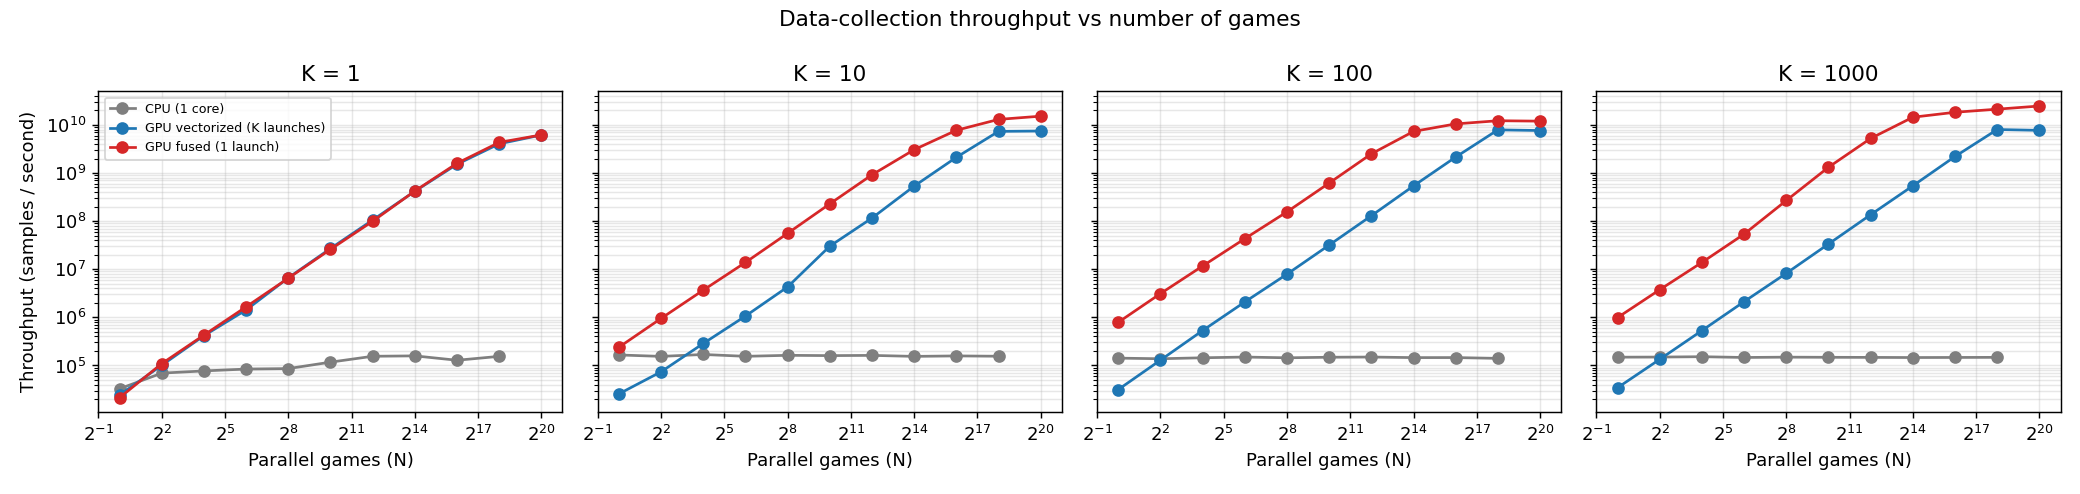

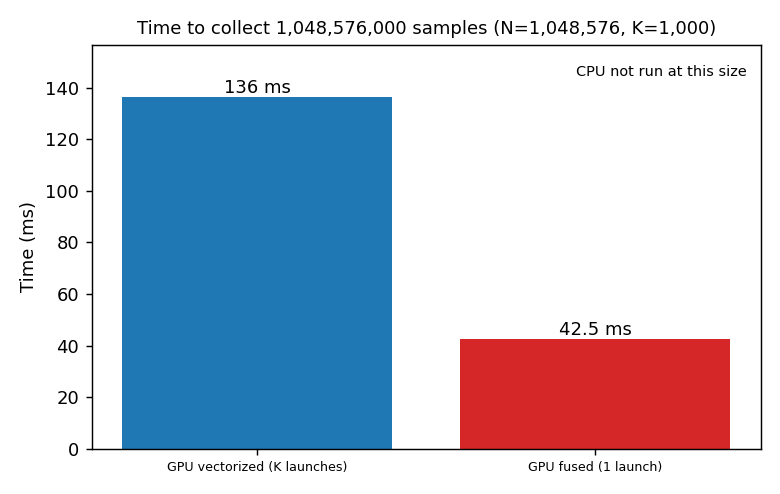

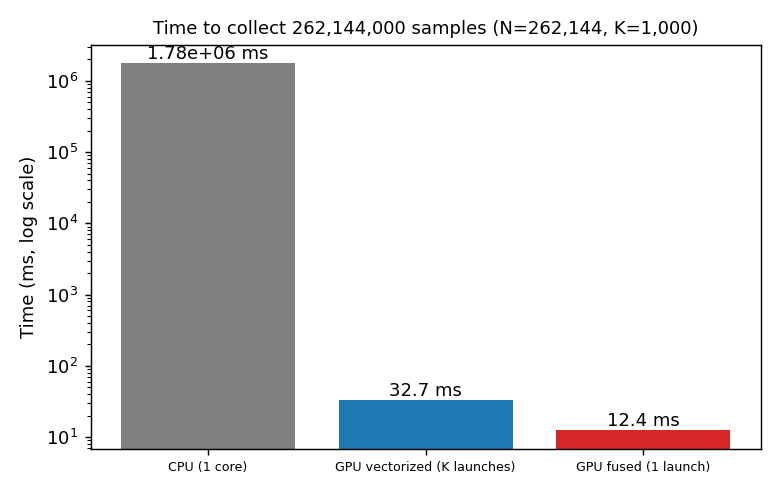

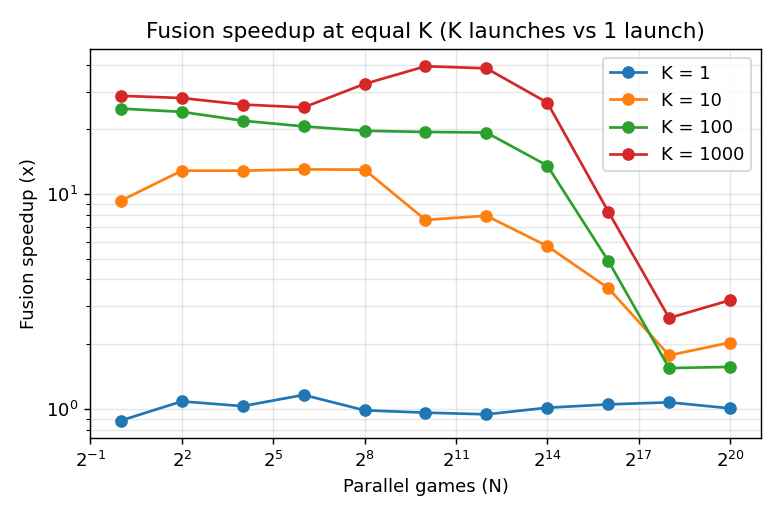

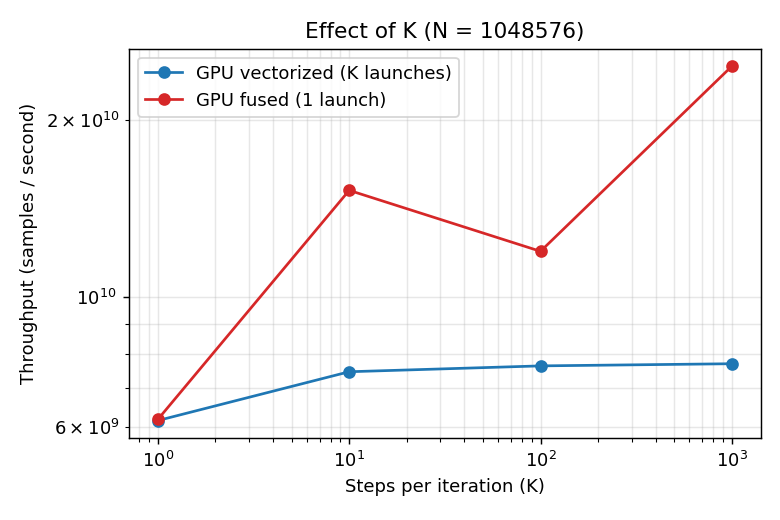

In [21]:
import os
from IPython.display import Image, display
for name in ["plot1_throughput_vs_N", "plot2_time_bars", "plot2b_time_bars_with_cpu",
             "plot3_fusion_speedup", "plot4_throughput_vs_K"]:
    if os.path.exists(f"results/{name}.png"):
        display(Image(f"results/{name}.png"))

## Step 19 - Create and show the animation

Makes two slow-motion replays that use the real measured times: `results/race.gif` for the **largest configuration measured** (N = 1,048,576, K = 1,000; GPU vectorized vs GPU fused, since the CPU was not run there)
and `results/race_with_cpu.gif` for the **largest configuration that includes the CPU** (all three approaches). Shows both.

NOTE: missing approaches for this configuration: ['cpu'] (use --with-cpu for a configuration with the CPU)
Saved results/race.gif  (N=1,048,576, K=1,000)
Saved results/race_with_cpu.gif  (N=262,144, K=1,000)


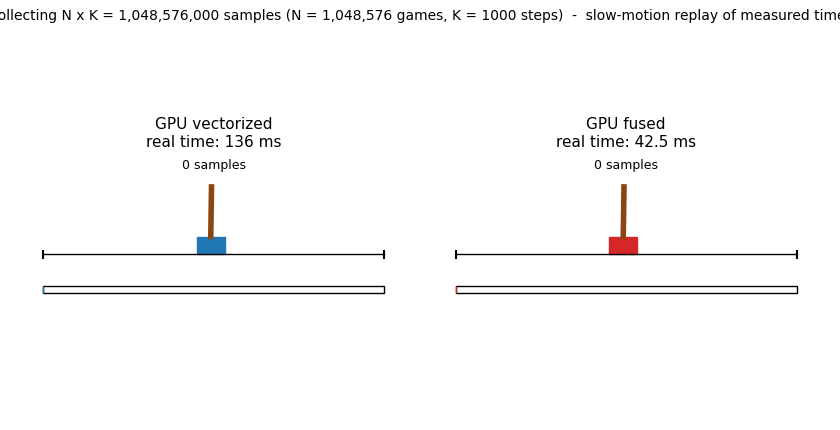

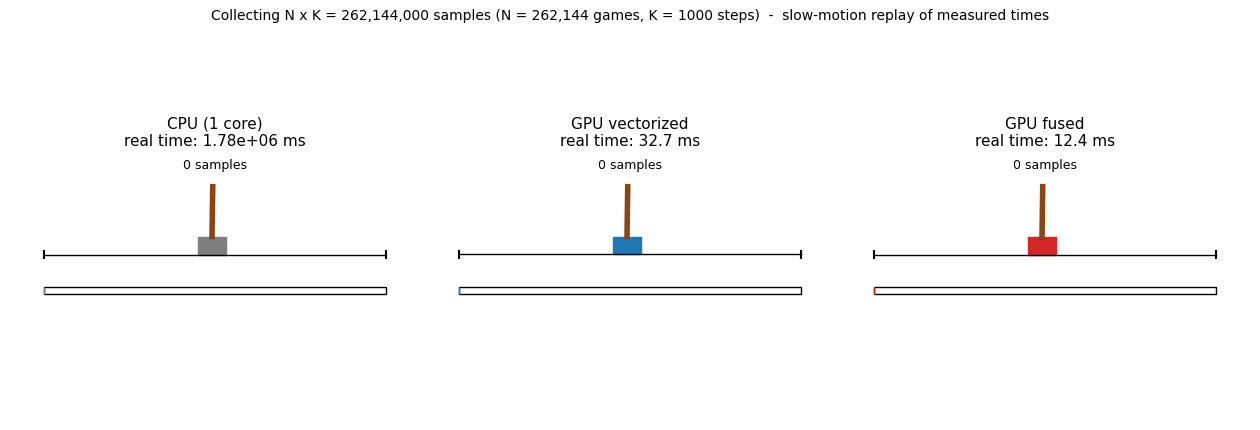

In [22]:
!python scripts/visualize.py --gif
!python scripts/visualize.py --with-cpu --gif
from IPython.display import Image, display
display(Image(filename="results/race.gif"))
display(Image(filename="results/race_with_cpu.gif"))

## Step 20 - Watch the live simulation

Runs the live demo inside the notebook, one approach after the other: first the CPU, then GPU vectorized, then GPU fused. Each approach simulates 256 games and draws the first one,
with 4 simulation steps between two frames, for 100 frames. Every approach gets its own animation block (it stays visible when it finishes), showing the robot cart and pole plus a live
counter of steps, samples and the **compute-only** time of that approach. When all three have run it prints the demo compute-only times. Needs the GPU.
To change it, edit `--games`, `--frames` or `--steps-per-frame`, or add `--only cpu` / `--only vectorized` / `--only fused` to run a single approach.

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


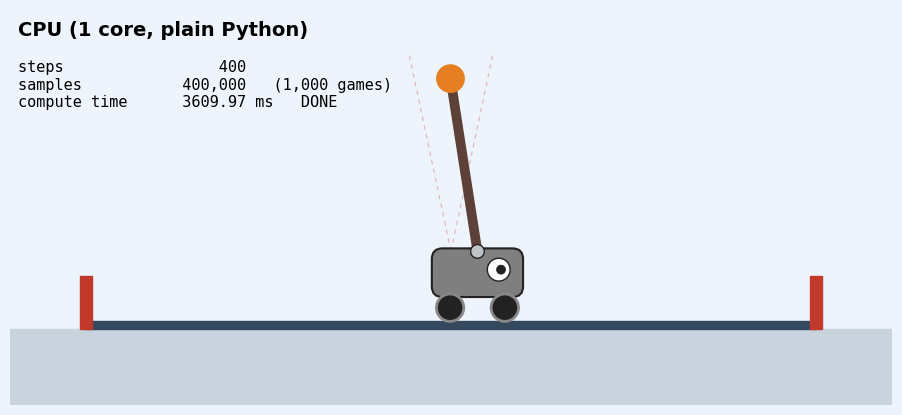

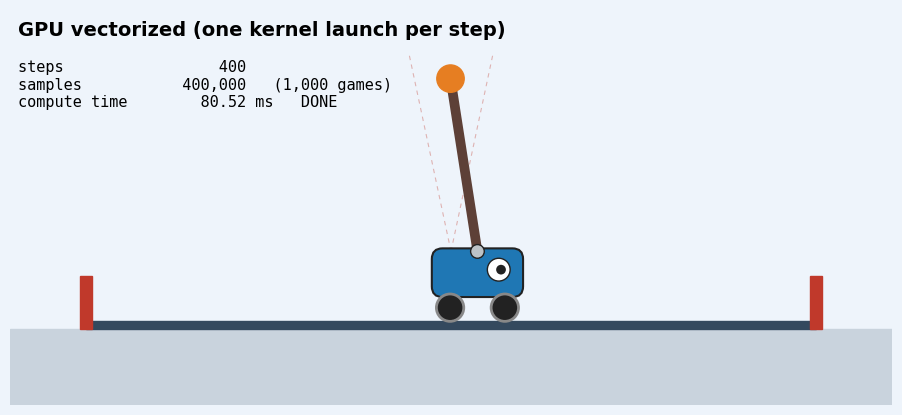

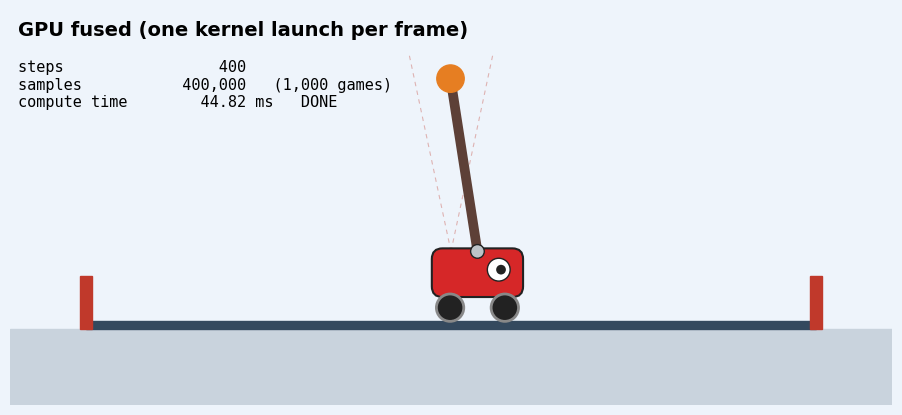


Demo compute-only times (1000 games, 400 steps; copy-back and drawing excluded):
  CPU (1 core, plain Python)                          3609.97 ms   (   9024.9 microseconds per step)
  GPU vectorized (one kernel launch per step)           80.52 ms   (    201.3 microseconds per step)
  GPU fused (one kernel launch per frame)               44.82 ms   (    112.0 microseconds per step)
These are demo-size numbers. The benchmark numbers come from the sweeps (src/run_sweeps.py).


<Figure size 640x480 with 0 Axes>

In [26]:
%run scripts/live_demo.py

## Step 21 - Save or download the results

Packs the `results/` folder into `results.zip`. On Colab this also starts the download; elsewhere the zip is just left in the working folder.

In [24]:
import shutil
shutil.make_archive("results", "zip", "results")
try:
    from google.colab import files
    files.download("results.zip")
except ImportError:
    print("Saved results.zip in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>